# Notebook 4 — Build a DBA ring

Build an electron storage ring from **double-bend achromat (DBA) cells**, using the same steps as in the FODO exercise. Match the cell, assemble the ring, and estimate its radiation equilibrium.

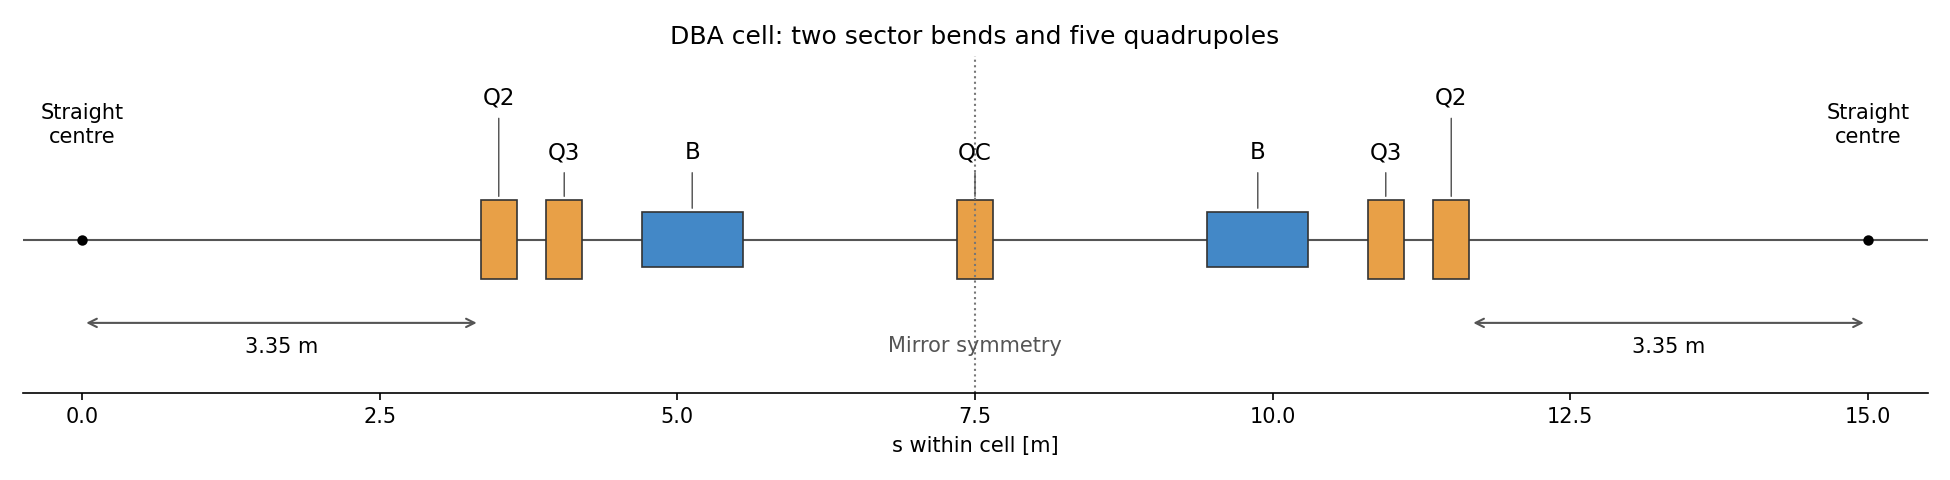

The sketch shows the longitudinal layout; magnet lengths and positions are to scale. The cell is mirror symmetric about QC. The adjoining 3.35 m end drifts form a 6.7 m magnet-free straight between cells.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle / total energy | Electron / 1.7 GeV |
| Circumference / number of cells | 240 m / 16 |
| Cell length | 15 m |
| Sector dipoles per cell / dipole length | 2 / 0.85 m |
| Quadrupoles per cell / quadrupole length | 5 / 0.30 m |
| Quadrupole families | Q2, Q3, QC |
| Ring tune targets | 17.84 / 6.82 |
| Straight-centre target | $D_x=0$ |

Use the following **magnet-centre positions**. The two magnets of each outer quadrupole family share one strength knob. Both dipoles have the same positive angle, $2\pi/32$, and no quadrupole gradient.

| Family | Centres within the cell [m] |
|---|---|
| Q2 | 3.50, 11.50 |
| Q3 | 4.05, 10.95 |
| Bend | 5.125, 9.875 |
| QC | 7.50 |

## Your tasks

1. **Create an Xtrack environment.** Set the reference electron and define variables for the magnet lengths, dipole angle, and independent strengths `kq2`, `kq3`, and `kqc`. Initialize the quadrupole strengths to zero for the geometry construction.
2. **Build the cell and plot its survey.** Position the magnets with `env.place(..., at=...)` and let Xtrack create the drifts. Add a marker named `ss` at the start of the cell, at the centre of a straight section.
3. **Calculate the initial optics.** Use the stable starting strengths `kq2 = 3.92`, `kq3 = -3.50`, and `kqc = 2.93`, in m$^{-2}$. Calculate and plot the periodic cell optics.
4. **Match the achromat.** Vary the three quadrupole strengths to obtain cell phase advances `qx = 17.84 / 16`, `qy = 6.82 / 16`, with `dx = 0` at `ss`. Inspect the matching targets and strengths, then plot the matched optics. Check the dispersion slope at the straight centre as well.
5. **Assemble the ring.** Repeat the cell 16 times and give the magnet occurrences unique names. Plot the ring survey and full-ring optics.
6. **Estimate the radiation equilibrium.** Use radiation integrals on a sliced copy of the ring to obtain the energy loss per turn, all three damping times, the RMS relative momentum spread, and both transverse geometric emittances.
7. **Plot curly H and the $I_5$ integrands.** Inspect one cell and compare with the FODO. How does the dispersion behave in the straight sections and in the bends? Explain why the DBA can have a lower emittance despite its higher energy loss per turn.

This is the BESSY II-inspired teaching geometry, not an operational machine model. The energy, circumference, and dipole count match the FODO exercise, while the bend lengths and optics differ. Sextupoles and RF are left for subsequent steps.

## Worked solution

### Create the environment and define the parameters

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

In [2]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

n_cells = 16
n_bends = 2 * n_cells

env['l_cell'] = 15.0
env['l_bend'] = 0.85
env['l_quad'] = 0.30
env['angle_bend'] = 2 * np.pi / n_bends

env['kq2'] = 0.0
env['kq3'] = 0.0
env['kqc'] = 0.0

### Define the magnets and build the cell

In [3]:
# Define elements
for name in ['q2', 'q3', 'qc']:
    env.new(name, xt.Quadrupole, length='l_quad', k1='k' + name)
env.new('bend', xt.Bend, length='l_bend', angle='angle_bend', k1=0)
env.new('ss', xt.Marker)

'ss'

In [4]:
# Define cell (positions refer to magnet centres)
cell = env.new_line(length=env['l_cell'], components=[
    env.place('ss',   at=0),
    env.place('q2',   at=3.50),
    env.place('q3',   at=4.05),
    env.place('bend', at=5.125),
    env.place('qc',   at=7.50),
    env.place('bend', at='l_cell - 5.125'),
    env.place('q3',   at='l_cell - 4.05'),
    env.place('q2',   at='l_cell - 3.50'),
])

### Survey the cell

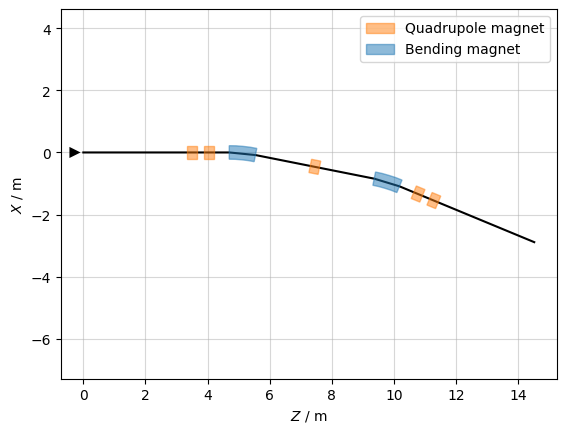

In [5]:
sv_cell = cell.survey()
sv_cell.plot()

### Set starting strengths and calculate the optics

Use a stable seed near the desired solution. The weak FODO settings do not provide a suitable starting point for this DBA match.

In [6]:
env['kq2'] = 3.92
env['kq3'] = -3.50
env['kqc'] = 2.93

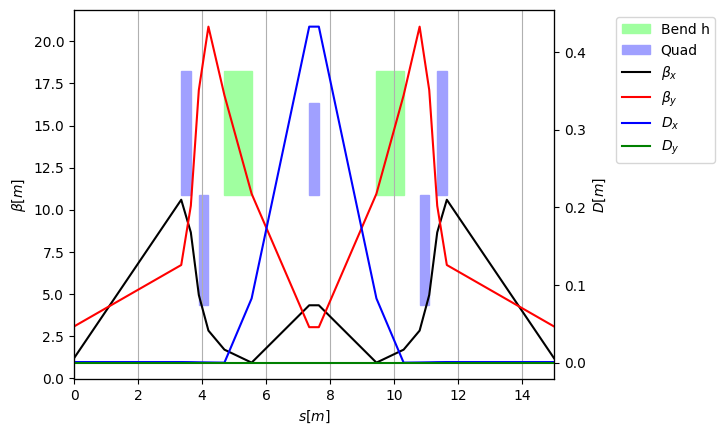

In [7]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Match the cell optics

The three families match both phase advances and zero dispersion at `ss`. The straight-centre beta is an outcome of the match, rather than a separate target. For this symmetric periodic cell, the dispersion slope at the straight centre vanishes by symmetry; check it after the match.

The phase advances are 401.4° and 153.45° per cell. The horizontal phase accumulates more than one full turn within a cell: use `17.84 / 16` without reducing it modulo one.

In [8]:
opt_cell = cell.match(
    solve=False,
    method='4d',
    vary=xt.VaryList(['kq2', 'kq3', 'kqc'], step=1e-5, limits=(-8, 8)),
    targets=[
        xt.TargetSet(qx=17.84 / n_cells, qy=6.82 / n_cells, tol=1e-8),
        xt.TargetSet(dx=0, at='ss', tol=1e-8),
    ],
)

In [9]:
opt_cell.target_status()

Target status:               
id state tag   tol_met       residue   current_val    target_val description                                 
0  ON    qx      False   -0.00304418       1.11196         1.115 'qx', val=1.115, tol=1e-08, weight=10       
1  ON    qy      False    0.00625954       0.43251       0.42625 'qy', val=0.42625, tol=1e-08, weight=10     
2  ON    ss_dx   False   0.000739854   0.000739854             0 ('dx', 'ss'), val=0, tol=1e-08, weight=1 ...


In [10]:
opt_cell.run_jacobian(30)

Optimize - start penalty: 0.07                         



Optimize - end penalty:  4.63471e-09                            


In [11]:
opt_cell.target_status()
opt_cell.vary_status()

Target status:               
id state tag   tol_met       residue   current_val    target_val description                                 
0  ON    qx       True  -4.29438e-10         1.115         1.115 'qx', val=1.115, tol=1e-08, weight=10       
1  ON    qy       True   1.41642e-10       0.42625       0.42625 'qy', val=0.42625, tol=1e-08, weight=10     
2  ON    ss_dx    True   1.01616e-10   1.01616e-10             0 ('dx', 'ss'), val=0, tol=1e-08, weight=1 ...
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kq2           -8       3.92496           8          3.92         1e-05             1
1  ON        OK  kq3           -8      -3.49527           8          -3.5         1e-05             1
2  ON        OK  kqc           -8       2.92835           8          2.93         1e-05             1


### Inspect the matched cell optics

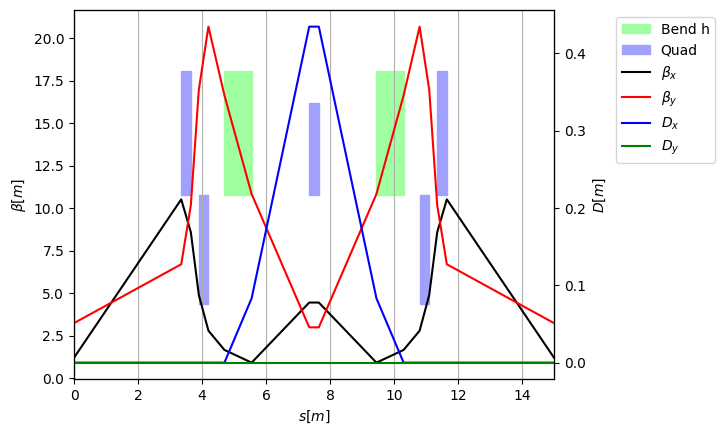

In [12]:
tw_cell = cell.twiss4d()
tw_cell.plot()

In [13]:
tw_cell.rows['ss'].cols['betx bety dx dpx']

TwissTable: 1 row, 5 cols
name          betx          bety            dx           dpx
ss         1.20427       3.24005   1.01616e-10  -7.08744e-12

### Assemble the ring

Repeat the cell 16 times, then give each magnet occurrence a unique name. The magnets remain linked to the same family variables.

In [14]:
ring = n_cells * cell
ring.replace_all_repeated_elements()

### Survey

In [15]:
sv = ring.survey()

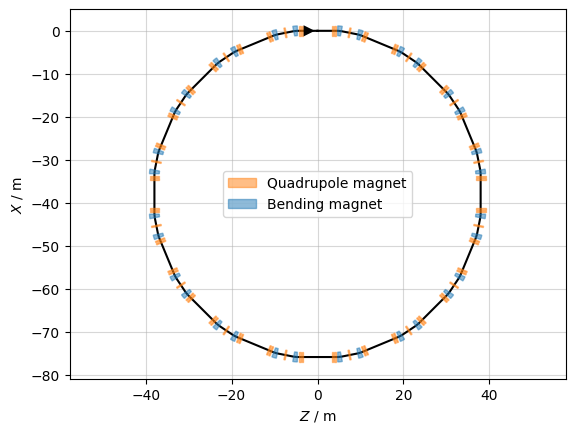

In [16]:
sv.plot()

### Full-ring optics

Ring tunes: 17.8400 / 6.8200


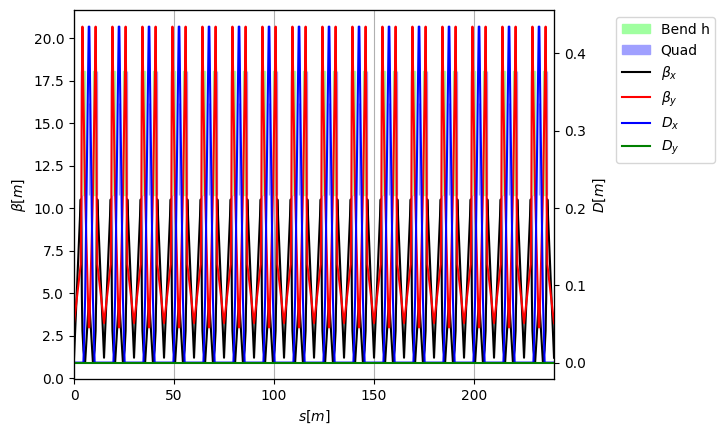

In [17]:
tw_ring = ring.twiss4d()
print(f'Ring tunes: {tw_ring.qx:.4f} / {tw_ring.qy:.4f}')
tw_ring.plot()

### Radiation integrals

Split the bends into thick slices to sample the optics along each magnet. Calculate the radiation integrals on this copy of the matched ring.

These are equilibrium estimates assuming that the mean energy loss is replenished. We can obtain them from the 4D optics without installing an RF cavity or enabling radiation in tracking. See the [radiation-integral outputs in the Xsuite reference](https://xsuite.readthedocs.io/en/latest/apireference.html).

We use eight slices per bend, as in the FODO exercise. For this DBA, the horizontal emittance estimate is about 0.55% higher than with 32 slices; increase the number of slices when a more precise comparison is needed.

In [18]:
ring_rad = ring.copy()
ring_rad.slice_thick_elements(slicing_strategies=[
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(8, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
])

tw_rad = ring_rad.twiss4d(radiation_integrals=True)

Slicing line:   0%|          | 0/256 [00:00<?, ?it/s]

### Energy loss, damping times, and equilibrium beam parameters

Damping times are the reciprocals of the amplitude damping rates. The emittances are geometric. In this ideal uncoupled planar model the vertical dispersion and vertical emittance are zero.

In [19]:
tw_rad.rad_int_energy_loss # eV

170673.8656231709

In [20]:
1 / tw_rad.rad_int_damping_constant_x_s # amplitude damping time [s]

0.016051602603229943

In [21]:
1 / tw_rad.rad_int_damping_constant_y_s # amplitude damping time [s]

0.01594786059880154

In [22]:
1 / tw_rad.rad_int_damping_constant_zeta_s # amplitude damping time [s]

0.007948245421321031

In [23]:
tw_rad.rad_int_sigma_delta

0.0006987600815839309

In [24]:
tw_rad.rad_int_eq_gemitt_x * 1e9 # [nm rad]

15.47869154373129

In [25]:
tw_rad.rad_int_eq_gemitt_y * 1e9 # [nm rad]

0.0

### Curly H and the $I_5$ integrand

$$
\mathcal{H}=\gamma D^2+2\alpha DD'+\beta D'^2,
\qquad I_5=\oint\frac{\mathcal{H}}{|\rho|^3}\,ds.
$$

(0.0, 15.0)

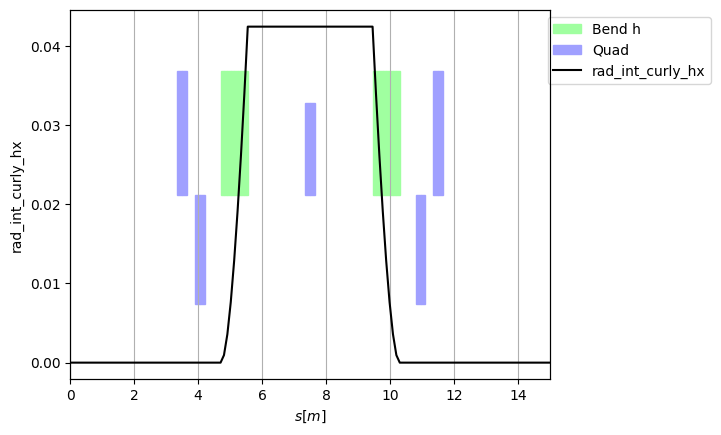

In [26]:
tw_rad.plot('rad_int_curly_hx')
plt.xlim(0, env['l_cell'])

(0.0, 15.0)

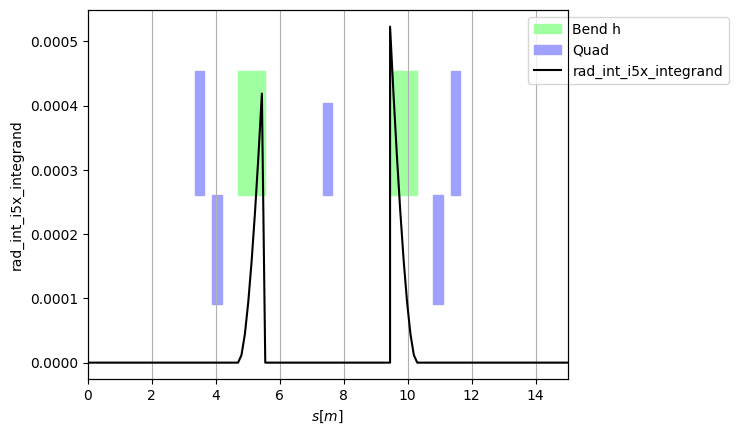

In [27]:
tw_rad.plot('rad_int_i5x_integrand')
plt.xlim(0, env['l_cell'])